# Introdução

No mundo das empresas de telecomunicações, que se baseia em providenciar serviços telefônicos a clientes mediante um pagamento, existe um grande interesse em manter esses clientes atrelados aos planos; afinal, existem muitas empresas concorrentes. Mas e se coletássemos dados desses clientes para prever quais clientes tendem a cancelar o plano, e quais tendem a permanecer? Esse é o intuito deste projeto. Através de Machine Learning, modelos serão criados com o propósito de identificar corretamente quais clientes cancelaram e quais não cancelaram o serviço.

Serão utilizadas certas estratégias dos itens complementares:

• Comparou pelo menos 5 algoritmos/pipelines diferentes (sem contar o baseline

• Utilizou de forma correta validação cruzada para comparar diferentes algoritmos/pipelines

• Realizou redução de dimensionalidade ou seleção de atributos nos dados, permitindo que o 
optuna controlasse esse processo (isto é, otimizando os hiperparâmetros destas estratégias) 
(nota: é necessário ter pelo menos 20 atributos para optar por esta estratégia)

• Fez alguma estratégia suficientemente interessante (e bem discutida na entrega) que não está 
contemplada nos demais itens

O projeto foi desenvolvido pelo grupo Guardiões das Árvores, com seu brasão identificado logo abaixo:

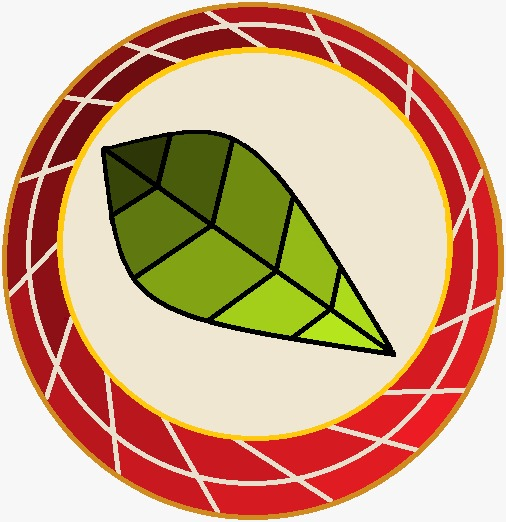

In [1]:
from IPython.display import Image

Image(filename = "Brasão Tiamat.jpeg")

##### Figura 0 - Brasão dos Guardiões da Floresta.

O dataset escolhido se chama Telco Customer Churn. Ele será importado agora:

In [2]:
import pandas as pd

link_dataset = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(link_dataset)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Como podemos ver, existe uma coluna chamada "customerID" que serve apenas para identificar cada indivíduo. Como ela é irrelevante em nosso contexto de Aprendizado de Máquina, ela será retirada.

In [3]:
df = df.drop(columns = "customerID")

# Análise Exploratória do Dataset:

## Compreendendo o tamanho do dataset e a classificação de atributos:

Como vimos acima, nosso dataset tem 7043 exemplos e 21 atributos (20 atributos + 1 target). A fim de compreender os dados, vamos realizar uma análise dos exemplos e atributos do dataset escolhido. Primeiro, identificaremos todas as colunas do dataset, com um resumo dos atributos:

In [4]:
import pandas as pd

colunas_num = df.select_dtypes(include=['number']).columns.tolist()
colunas_cat = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"======== RESUMO DOS ATRIBUTOS ========")
print(f"\nAtributos numéricos ({len(colunas_num)}):")
for coluna in colunas_num:
    print(f"  - {coluna}")

print(f"\nAtributos categóricos ({len(colunas_cat)}):")
for coluna in colunas_cat:
    print(f"  - {coluna}")

print(f"\nTotal de instâncias (linhas): {df.shape[0]}")
print(f"Total de atributos (colunas): {df.shape[1]}")


======== RESUMO DOS ATRIBUTOS ========

Atributos numéricos (3):
  - SeniorCitizen
  - tenure
  - MonthlyCharges

Atributos categóricos (17):
  - gender
  - Partner
  - Dependents
  - PhoneService
  - MultipleLines
  - InternetService
  - OnlineSecurity
  - OnlineBackup
  - DeviceProtection
  - TechSupport
  - StreamingTV
  - StreamingMovies
  - Contract
  - PaperlessBilling
  - PaymentMethod
  - TotalCharges
  - Churn

Total de instâncias (linhas): 7043
Total de atributos (colunas): 20


Com essa divisão, vemos que a coluna TotalCharges, que deveria ser classificada como numérica, foi classificada como categórica. Além disso, instâncias com o atributo tenure = 0 apresentam o atributo TotalCharges com valor Nan ao invés de 0. Esses problemas serão resolvidos.

A coluna SeniorCitizen, que é categórica binária, foi interpretada como numérica por causa de seus valores (0 e 1). Também vamos arrumar isso

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors = "coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [6]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

E os valores ausentes remanescentes? Vamos checar se tem algum.

In [7]:
print(f"• Valores ausentes remanescentes: {df.isnull().sum().sum()}")

• Valores ausentes remanescentes: 0


## Estatísticas Descritivas e Distribuição:

Veremos como os valores dos atributos numéricos se distribuem (média, desvio padrão, mínimo, máximo), e se há a presença de outliers.

In [8]:
descricao_num = df.describe()
display(descricao_num.round(2))

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


Vamos interpretar os atributos numéricos, considerando o contexto do dataset:

Tenure é o tempo de contrato, e ele varia de 0 a 72 meses (0 a 6 anos). Em média, esse tempo equivale a 32.37 meses, mas a mediana equivale a 29.00 meses e o desvio padrão é de 24.56 meses, sugerindo que existam 2 grupos de clientes: os que recém-assinantes e os assinantes fiéis.

MonthlyCharges representa a cobrança mensal pelo serviço, sendo o mínimo 18.25 e o máximo 118.75, mas com mediana em 70.35 e média 64.76, sugerindo que a maior parte dos assinantes opte por planos de maior valor agregado.

TotalCharges corresponde ao montante acumulado de todas as cobranças mensais. Como apresenta forte dependência linear com o tempo de contrato (tenure), esta métrica evidencia o valor de receita gerado pelos clientes de maior retenção.

Agora, 4 atributos categóricos serão analisados na Figura $1$: `Contract`, `InternetService`, `PaymentMethod` e `PaperlessBilling`. Esses atributos foram escolhidos porque, na literatura de telecomunicações (referências [1], [2] e [3]), eles estão dentro das dimensões de maior impacto no Churn: o custo de transição contratual (Contract), a qualidade percebida do serviço central (InternetService), e a fricção operacional de pagamento e engajamento (PaymentMethod e PaperlessBilling).

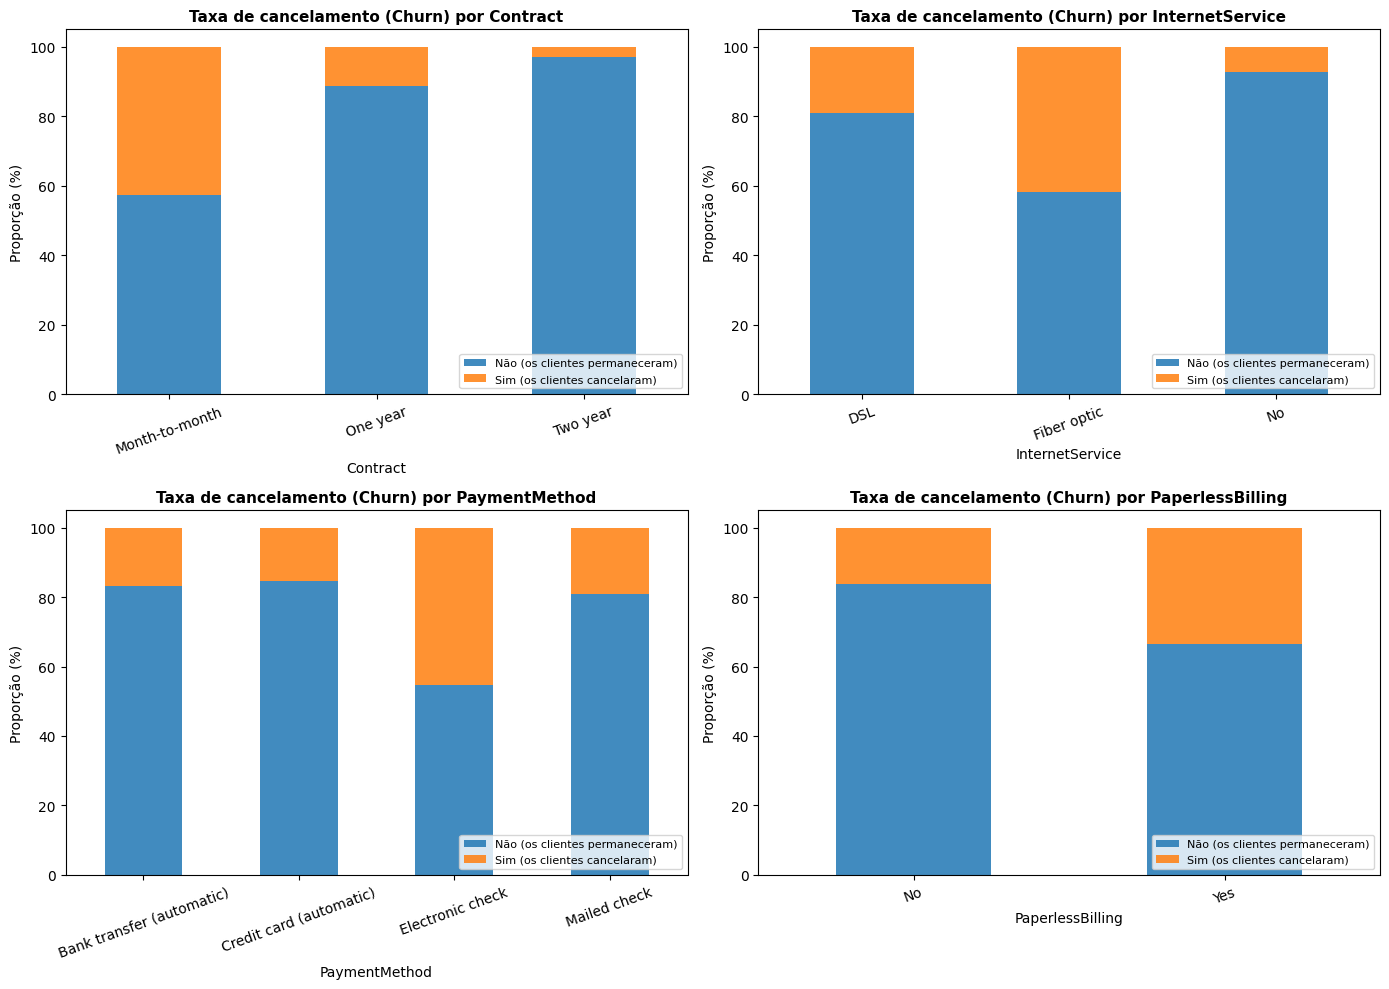

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

atributos_cat_EDA = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, coluna in enumerate(atributos_cat_EDA):
    df_prop = df.groupby(coluna)["Churn"].value_counts(normalize=True).unstack() * 100
    df_prop.plot(kind="bar", stacked=True, ax=axes[i], alpha=0.85)
    axes[i].set_title(f"Taxa de cancelamento (Churn) por {coluna}", fontsize=11, fontweight="bold")
    axes[i].set_xlabel(coluna, fontsize=10)
    axes[i].set_ylabel("Proporção (%)", fontsize=10)
    axes[i].legend(["Não (os clientes permaneceram)", "Sim (os clientes cancelaram)"], loc="lower right", fontsize=8)
    axes[i].tick_params(axis = "x", rotation = 20)

plt.tight_layout()
plt.show()

##### Figura 1 - Análise de 4 atributos categóricos com alta influência sob o target Churn, por meio de gráficos de barras. Imagem gerada com auxílio da AI Gemini.

Que interessante! O gráfico acima nos apresenta relações interessantes entre os atributos e os valores dos dados para cada atributo.

`Contract` diz respeito ao tipo de plano escolhido: mensal, 1 ano ou 2 anos. Ele se destaca como preditor categórico mais forte (entre os 4 atributos analisados), e nos revela que clientes com planos mensais costumam cancelar mais do que clientes com planos anuais (1 ou 2 anos).

`InternetService` é referente ao serviço de internet, que pode ser: sem serviço (no), DSL ou Fiber optic. Esse atributo mostra que clientes que optam por serviço de internet, em específico o mais caro (Fiber optic), cancelam mais. Isso sugere aspectos do Churn ligados ao custo.

`PaymentMethod`, ligado ao método de pagamento, é bem interessante: se em InternetService vimos que custos maiores podem significar uma maior taxa de Churn, aqui analisamos como o método de pagamento (sem considerar o custo) influencia o Churn. No geral, os métodos de pagamento não influenciam muito o Churn, já que 3 deles apresentam uma taxa de Churn muito semelhante. Entretanto, note que o pagamento por cheque eletrônico se destaca: quase metade dos clientes cancelam. Isso indica que o pagamento eletrônico não é uma estratégia de pagamento vantajosa para as empresas de telecomunicações.

`PaperlessBilling`, que diz respeito à fatura dos clientes (se ela é digital ou física/em papel), nos indica o seguinte: clientes com faturas digitais (PaperlessBilling = Yes) demonstram uma propensão ao Churn consideravelmente maior do que os adeptos da fatura física. Do ponto de vista comportamental, essa variável atua como um indicador de clientes altamente digitais e menos amarrados a vínculos físicos, facilitando o Churn e a migração para concorrentes.

Seria muito interessante calcular a **correlação de Pearson** dos atributos categóricos, para checar se o dataset está alinhado à literatura quanto a correlação entre os atributos destacados acima e o target. Como esses atributos ainda não foram codificados, **primeiro os dados serão tratados** e depois será calculada a correlação.

O próximo passo é verificar a distribuição do target Churn, um target binário que indica se os clientes cancelaram ou serviço ou não, por meio da Figura $2$.

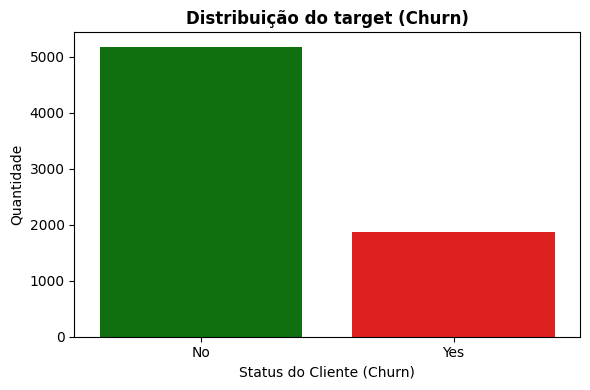

In [10]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x = "Churn", hue = "Churn", data = df, palette = ["Green", "Red"])
plt.title("Distribuição do target (Churn)", fontsize = 12, fontweight = "bold")
plt.xlabel("Status do Cliente (Churn)", fontsize = 10)
plt.ylabel("Quantidade", fontsize = 10)


plt.tight_layout()
plt.show()

##### Figura 2 - gráfico de barras que demonstra a distribuição dos valores para o target Churn

In [11]:
lista_no = []
lista_yes = []

for valor in df["Churn"]:
    if valor == "No":
        lista_no.append(valor)
    elif valor == "Yes":
        lista_yes.append(valor)
    else:
        print("Existe algum target com valor diferente de Yes ou No")

len_yes_no = len(lista_no) + len(lista_yes)
if len_yes_no == len(df["Churn"]):
    print("Todos os dados do target Churn apresentam valor sendo Yes ou No; Churn é um target binário")

print(f"Porcentagem valores Yes: {(len(lista_yes)/len_yes_no) * 100}%")
print(f"Porcentagem valores No: {(len(lista_no)/len_yes_no) * 100}%")

Todos os dados do target Churn apresentam valor sendo Yes ou No; Churn é um target binário
Porcentagem valores Yes: 26.536987079369588%
Porcentagem valores No: 73.4630129206304%


Analisando o gráfico da Figura $2$ e a porcentagem de valores, notamos que aproximadamente 26.5% dos clientes do dataset (ou cerca de $1.869$ individuos) cancelaram o serviço, enquanto 73.4% (aproximadamente $5174$ indivíduos) permaneceram com o serviço. Isso indica que o target está desbalanceado.

Como temos dados desbalanceados, utilizar apenas uma métrica simples como Acurácia não é adequado, o que justifica a priorização de métricas como F1-Score e ROC-AUC, orientadas à classe minoritária. Posteriormente, será utilizada a estratégia SMOTE para corrigir o desbalanceamento, mas mesmo assim a divisão e validação cruzada dos dados considerarão dados desbalanceados.

# Preparação dos dados:

## Divisão train_test_split

Nesta etapa, vamos dividir os dados que serão utilizados para treinar e testar os modelos. dados_x se refere aos atributos, e dados_y são os dados do target. Existe uma sensibilidade para compreender que, como o target tem uma distribuição desbalanceada, a divisão treino/teste deve considerar esse desbalanço. Por esse motivo, os dados foram estratificados no trecho (stratify = dados_y), na segunda célula de código abaixo. Também estudaremos as dimensões dos dados divididos.

In [12]:
dados_x = df.drop(columns = ["Churn"])
dados_y = df["Churn"]

In [13]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(dados_x, dados_y, test_size = 0.2, random_state = 42, stratify = dados_y)

In [14]:
print(f"• Dimensões de X_train (Treino): {X_treino.shape}")
print(f"• Dimensões de X_test (Teste): {X_teste.shape}")
print(f"• Distribuição do Churn no Treino:\n{y_treino.value_counts(normalize=True).round(4) * 100}")

• Dimensões de X_train (Treino): (5634, 19)
• Dimensões de X_test (Teste): (1409, 19)
• Distribuição do Churn no Treino:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Maravilha! Temos 5634 exemplos nos dados de treino, e 1409 exemplos nos dados de teste. A distribuição de Churn no treino segue a distribuição do DataFrame, o que minimiza os efeitos do desbalanceamento dos dados.

## Normalização

Agora, vamos normalizar os nossos dados numéricos. Como a divisão entre target, atributos, treino e teste já foi feita, agora podemos normalizar tranquilamente os dados numéricos sem nos preocupar com vazamento de dados. Essa etapa é muito importante para algoritmos como KNN e Regressão Logística, a fim de evitar que um atributo tenha um peso desproporcionalmente maior que outros atributos. A normalização StandardScaler do Sklearn é calculada da seguinte maneira:

$$
z = (x - u)/s
$$
Onde *z* é o valor normalizado, *x* é o valor original, *u* é a média dos valores num determinado atributo, e *s* é o desvio padrão dos valores num determinado atributo.

In [15]:
from sklearn.preprocessing import StandardScaler

colunas_num = X_treino.select_dtypes(include = ["int", "float64"]).columns.tolist()

scaler = StandardScaler()

X_treino_num = scaler.fit_transform(X_treino[colunas_num])
X_teste_num = scaler.transform(X_teste[colunas_num])

# Converter para DataFrame
X_treino_num_df = pd.DataFrame(X_treino_num, columns = colunas_num, index = X_treino.index)
X_teste_num_df = pd.DataFrame(X_teste_num, columns = colunas_num, index = X_teste.index)

## One Hot Encoder

Os dados dos atributos categóricos serão convertidos em numéricos (valores de 0 ou 1) por meio do One Hot Encoder, cumprindo os requisitos para treinar modelos como KNN.

Nesta etapa, os dados do target também serão convertidos para numéricos.

In [16]:
from sklearn.preprocessing import OneHotEncoder

colunas_cat = X_treino.select_dtypes(include = ["object", "category"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown = "ignore", sparse_output=False)

X_treino_cat = encoder.fit_transform(X_treino[colunas_cat])
X_teste_cat = encoder.transform(X_teste[colunas_cat])

nomes_atributos_cat = encoder.get_feature_names_out(colunas_cat)
X_treino_cat_df = pd.DataFrame(X_treino_cat, columns = nomes_atributos_cat, index = X_treino.index)
X_teste_cat_df = pd.DataFrame(X_teste_cat, columns = nomes_atributos_cat, index = X_teste.index)

y_treino = y_treino.map({"No": 0, "Yes": 1})
y_teste = y_teste.map({"No": 0, "Yes": 1})

print(f"Novas dimensões dos atributos categóricos codificados: {X_treino_cat_df.shape}")

Novas dimensões dos atributos categóricos codificados: (5634, 43)


Por fim, vamos juntar os dados categóricos codificados com os dados numéricos normalizados.

In [17]:
X_treino = pd.concat([X_treino_num_df, X_treino_cat_df], axis=1)
X_teste = pd.concat([X_teste_num_df, X_teste_cat_df], axis=1)

print(f"Dimensões finais de X_treino para os modelos: {X_treino.shape}")
print(f"Dimensões finais de X_teste para os modelos: {X_teste.shape}")

Dimensões finais de X_treino para os modelos: (5634, 46)
Dimensões finais de X_teste para os modelos: (1409, 46)


## Correlação de Pearson

A correlação de Pearson é uma estratégia utilizada para calcular a força da relação linear entre duas variáveis (quantitativas e contínuas) por meio da covariância, resultando num valor em [-1, 1]. O cálculo da correlação de Pearson é dado pela seguinte expressão:

\begin{equation}
\rho_{XY} = \mathrm{Corr}(X,Y) = \frac{\mathrm{Cov}(X, Y)}{\sigma_X \sigma_Y}
\end{equation}

Foi discutido anteriormente sobre 4 atributos categóricos em específico, que, de acordo com referências da literatura, teoricamente seriam mais influentes sob o target Churn do que os outros atributos. Isso será verificado para este dataset por meio do cálculo da correlação de Pearson para todos os atributos. Só um detalhe: o target Churn tem valores categóricos que serão temporariamente convertidos para numéricos, para viabilizar o cálculo da correlação.

In [18]:
df_encoded = pd.get_dummies(df, drop_first=True)

if "Churn" in df.columns:
    df_encoded["Churn_num"] = df["Churn"].map({"Yes": 1, "No": 0})
elif "Churn_Yes" in df_encoded.columns:
    df_encoded["Churn_num"] = df_encoded["Churn_Yes"].astype(int)

correlacoes = df_encoded.corr(numeric_only = True)["Churn_num"].drop(labels = ["Churn_num"], errors = "ignore")

df_corr = pd.DataFrame({"Atributo": correlacoes.index, "Correlacao_Pearson": correlacoes.values})

df_corr["Forca_de_Correlação"] = df_corr["Correlacao_Pearson"].abs()
df_corr = df_corr.sort_values(by = "Forca_de_Correlação", ascending = False).reset_index(drop = True)
df_corr = df_corr[["Atributo", "Correlacao_Pearson"]]
df_corr = df_corr.iloc[1:].reset_index(drop = True)

print("--- Tabela Completa de Correlação de Pearson (Numéricas + Categóricas Codificadas) ---")
display(df_corr)

--- Tabela Completa de Correlação de Pearson (Numéricas + Categóricas Codificadas) ---


,Atributo,Correlacao_Pearson
0,tenure,-0.352229
1,InternetService_Fiber optic,0.308020
2,Contract_Two year,-0.302253
3,PaymentMethod_Electronic check,0.301919
4,InternetService_No,-0.227890
5,OnlineBackup_No internet service,-0.227890
6,DeviceProtection_No internet service,-0.227890
7,StreamingTV_No internet service,-0.227890
8,TechSupport_No internet service,-0.227890
9,StreamingMovies_No internet service,-0.227890


Vamos relembrar quais eram os 4 atributos destacados anteriormente: `Contract`, `InternetService`, `PaymentMethod` e `PaperlessBilling`. Analisando a tabela, nota-se que nenhum atributo teve correlação maior do que `tenure`, com $r = -0.352229$, que configura uma correlação média-baixa. Os atributos destacados (representados por suas respectivas categoricas após a codificação) obtiveram um bom ranking na tabela, ocupando as posições logo abaixo de `tenure` (com exceção de `PaperlessBilling`, que ficou na 13ª posição). O dataset é apenas uma amostra de todos os clientes de empresas de Telecom no mundo e não representa a verdade absoluta, então conclui-se que existe uma relação interessante entre os dados e a literatura, pois a correlação de atributos atingiu parcialmente o que foi esperado pela literatura. Na seção de otimização de hiperparâmetros, será utilizado o SelectKBest para identificar quais atributos são os mais importantes para treinar os modelos. Esse processo será feito a partir dos padrões do Optuna, mas essa discussão é interessante para compreender como os atributos mais influentes podem ser selecionados.

## Ajustando os dados desbalanceados - SMOTE

Como os dados são desbalanceados, existe um viés nos dados de treino que pode prejudicar o treinamento dos modelos. Se existem mais dados sobre pessoas que não cancelaram o plano do que as que cancelaram. fica difícil compreender os parâmetros que resultam em mais cancelamentos. É aí que entra o SMOTE - Synthetic Minority Over-sampling Technic.

O papel do SMOTE é analisar a classe minoritária do target (neste caso, quando o cliente cancelou o serviço) e ampliá-la. Há uma sensibilidade nisso: se os dados forem simplesmente duplicados para balancear o dataset, um overfitting será causado e os modelos apenas decorarão os exemplos exatos. Então, é necessário analisar o espaço multidimensional dos atributos envolvidos nos dados minoritários e, a partir disso, criar um novo dado sintético (um ponto nesse espaço multidimensional) que é parecido com os dados reais, mas não é igual.

E como o SMOTE opera matematicamente? Ele escolhe um ponto inicial no espaço multidimensional da classe minoritária, calcula a distância euclidiana entre esse ponto e seus vizinhos mais próximos, escolhe um vizinho aleatório e cria um ponto sintético entre o ponto inicial e esse vizinho. Esse processo é repetido até que os dados sejam balanceados.

Os parâmetros envolvidos no SMOTE são:
- Número de vizinhos próximos que serão considerados
- Métrica para calcular a distância entre o ponto inicial e um vizinho aleatório
- Número de pontos sintéticos a serem criados (depende do limite entre dados balanceados e desbalanceados)

Na célula abaixo, o SMOTE será importado, e verificaremos as dimensões dos dados de treino antes e após a aplicação do SMOTE. Note que esta célula serve apenas para analisar os efeitos do SMOTE sobre os dados, mas sua verdadeira implementação se dará no pipeline do Optuna, onde ele criará dados sintéticos dentro de cada fold da validação cruzada, e não do x_treino inteiro. Isso evita vazamento de dados.

In [19]:
import sys
!{sys.executable} -m pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)

X_treino_smote, y_treino_smote = smote.fit_resample(X_treino, y_treino)

print(f"Dimensões de X_treino antes do SMOTE: {X_treino.shape}")
print(f"Dimensões de X_treino após o SMOTE:  {X_treino_smote.shape}")
print(f"\nDistribuição do Target após o SMOTE:\n{y_treino_smote.value_counts()}")


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: c:\venv\ilumpy\Scripts\python.exe -m pip install --upgrade pip


Dimensões de X_treino antes do SMOTE: (5634, 46)
Dimensões de X_treino após o SMOTE:  (8278, 46)

Distribuição do Target após o SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


# Modelos e Otimização de hiperparâmetros

## Baseline

Começaremos criando um modelo baseline simples e sem validação cruzada. As métricas de avaliação de desempenho do modelo serão ROC-AUC e F1 Score, dado o target desbalanceado. A estratégia "stratified" utilizada no DummyClassifier retorna os resultados do Baseline em probabilidades, necessário para calcular o ROC-AUC.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, roc_auc_score

baseline = DummyClassifier(strategy = "stratified", random_state = 42)

baseline.fit(X_treino, y_treino)

y_previsao_baseline = baseline.predict(X_teste)
y_prob_baseline = baseline.predict_proba(X_teste)[:, 1]

f1_baseline = f1_score(y_teste, y_previsao_baseline)
roc_auc_baseline = roc_auc_score(y_teste, y_prob_baseline)

print("======== RESULTADOS DO BASELINE (DummyClassifier) ========")
print(f"F1-Score (Classe 1): {f1_baseline:.4f}")
print(f"ROC-AUC:             {roc_auc_baseline:.4f}")

======== RESULTADOS DO BASELINE (DummyClassifier) ========
F1-Score (Classe 1): 0.2903
ROC-AUC:             0.5163


Com os resultados do baseline, vemos que o F1 Score e o ROC-AUC são muito baixos (valores perto de 0.0 e de 0.5, respectivamente). Comparando esses resultados com o desbalanceamento do target, percebemos que o modelo detecta os clientes que não cancelam o serviço (no churn), mas erra aqueles que cancelam (churn). O objetivo aqui é detectar os clientes que cancelam o serviço, que são a minoria, para compreender por quê eles dão churn e como os atributos estão relacionados com isso.

No próximo passo, vamos criar funções que utilizam o Optuna para otimizar os hiperparâmetros em cada modelo, ajustando de pesos de classes e melhorando significativamente a detecção de churn (de forma correta). Primeiro os modelos serão criados, e depois vamos comparar os resultados de cada modelo.

## Regressão Logística e as funções objetivo

Chegou a hora de criar os modelos (baseline não conta). Como os hiperparâmetros serão otimizados para cada modelo criado, pois cada modelo é matematicamente diferente e requer uma otimização diferente, serão criadas funções objetivo para cada modelo. Cada função objetivo cria e otimiza os modelos com o Optuna, recebendo apenas 1 argumento: quantos modelos criar; elas retornam o melhor modelo encontrado. As etapas da otimização serão praticamente iguais para cada modelo, então vamos discuti-las agora enquanto criamos nosso primeiro modelo (Regressão Logística).

No processo de otimização, o objetivo é encontrar qual hiperparâmetro fornecerá os melhores resultados ao modelo que estamos criando. Isso envolve desconsiderar alguns atributos caso isso seja vantajoso (Seleção de Atributos - seleciona $k$ atributos. É importante ressaltar que vamos utilizar Validação Cruzada com 5 folds durante a otimização. Será criada a função objetivo_regressao_logistica, que rodará pelo Optuna 100 vezes e define as regras para criar e treinar a Regressão Logística; o Optuna selecionará qual é o melhor conjunto de hiperparâmetros a partir dessa função, além de ajustar a regularização $C$ para evitar overfitting ou underfitting. Por fim, a métrica utilizada para avaliar os modelos de cada função objetivo será ROC-AUC, sendo que F1 Score apenas será implementado no treinamento dos melhores modelos. Implementar o F1 Score durante a otimização pode fazer com que o Optuna descarte bons modelos, pois o F1 Score pode despencar abruptamente durante a otimização (o que não reflete o resultado final), e o Optuna pode considerar que um modelo é ruim no meio da otimização e descartá-lo (Pruning, ou poda), mesmo que não seja um modelo ruim.

É importante discutir sobre o custo computacional: modelos mais complexos tendem a ter um custo mais elevado, e utilizar estratégias como Validação Cruzada e SMOTE pode aumentar esse custo. O custo computacional é muito importante em Machine Learning, pois serve como uma ferramenta comparativa de custo benefício entre os desempenhos de modelos. Esse tópico será abordado novamente na seção Conclusão.

O primeiro modelo a ser criado é o de Regressão Logística. Nesse modelo, uma curva sigmoidal (em formato de "S") é ajustada de acordo com os dados do dataset, e os parâmetros definem uma divisória horizontal dessa curva: tudo que está acima receberá uma classificação, e tudo que está abaixo, outra classificação.

In [21]:
import optuna
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo_regressao_logistica(trial):
    """Função Objetivo para o algoritmo Regressão Logística"""
    k_atributos = trial.suggest_int("k_features", 5, X_treino.shape[1])

    lim_min_em_log_10 = 1e-4
    lim_max_em_log_10 = 1e2
    regularizacao_c = trial.suggest_float("C", lim_min_em_log_10, lim_max_em_log_10, log = True)
    
    seletor = SelectKBest(score_func = f_classif, k = k_atributos)
    modelo_reg_linear = LogisticRegression(C = regularizacao_c, max_iter = 1000, random_state = 42)

    pipeline = ImbPipeline([
        ("smote", smote),
        ("selector", seletor),
        ("classifier", modelo_reg_linear)
    ])
    
    valid_cruzada = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    resultados_roc_auc = cross_val_score(pipeline, X_treino, y_treino, cv = valid_cruzada, scoring = "roc_auc")
    return resultados_roc_auc.mean()

## KNearest Neighbors Classifier

O KNN é um modelo que consiste em classificar pontos no espaço a partir das características seus $K$ vizinhos mais próximos (não confundir com os $k$ atributos escolhidos durante a Redução de Dimensionalidade pelo Optuna); com apenas 2 atributos, é semelhante a colocar todos os pontos em um plano e classificar os desconhecidos a partir dos pontos mais próximos. Como temos 46 atributos, isso será feito em um hiperplano de 46 dimensões.

Os parãmetros do KNN também serão otimizados pelo Optuna: distância, K vizinhos e peso/ponderação do valor das distâncias. Para a distância entre cada ponto, o Optuna testará as métricas Manhattan e Euclidiana (p = 1 e p = 2 na distância de Minkowski, respectivamente; também vamos testar a ponderação uniforme e a ponderação com peso entre distâncias diferentes. O parâmetro $K$ vizinhos será otimizado no intervalo 3 <= $K$ <= 50.

In [22]:
from sklearn.neighbors import KNeighborsClassifier

def objetivo_knn(trial):
    """Função Objetivo para o algoritmo KNNClassifier"""
    k_atributos = trial.suggest_int("k_features", 5, X_treino.shape[1])
    
    K_vizinhos = trial.suggest_int("n_neighbors", 3, 50)
    ponderacao = trial.suggest_categorical("weights", ["uniform", "distance"]) # Ponderação
    distancia_p = trial.suggest_int("p", 1, 2)
    
    seletor = SelectKBest(score_func = f_classif, k = k_atributos)
    modelo_knn = KNeighborsClassifier(n_neighbors = K_vizinhos, weights = ponderacao, p = distancia_p)

    pipeline = ImbPipeline([
        ("smote", smote),
        ("selector", seletor),
        ("classifier", modelo_knn)
    ])
    
    valid_cruzada = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    resultados_knn = cross_val_score(pipeline, X_treino, y_treino, cv = valid_cruzada, scoring = "roc_auc")
    
    return resultados_knn.mean()

## Árvore de Decisão

A Árvore de Decisão é um modelo que pode ser representado visualmente por uma árvore de natal, e consiste em dividir os dados a partir de um fluxograma de perguntas de Verdadeiro ou Falso (exemplo: o cliente tem serviço de internet?). Cada divisão se chama split, e o conjunto de dados imediatamente antes de serem divididos é chamado de nó. Geralmente, se a resposta for True, o dado segue para a folha da esquerda; se for False, vai para a folha da direita. Essas etapas são repetidas até a árvore atingir uma profundidade (depth) determinada.

Os parâmetros da Árvore de Decisão que vamos otimizar com o Optuna são: profundidade máxima (max_depth) entre 3 e 30, número mínimo de dados para splitar um nó (min_samples_split) entre 2 e 30, e número mínimo de amostras em uma folha (min_samples_leaf) entre 1 e 20.

In [23]:
from sklearn.tree import DecisionTreeClassifier

def objetivo_arvore(trial):
    """Função Objetivo para o algoritmo Árvore de Decisão"""
    k_atributos = trial.suggest_int("k_features", 5, X_treino.shape[1])
    
    # Hiperparâmetros de controle de complexidade da Árvore para evitar overfitting
    max_depth = trial.suggest_int("max_depth", 3, 30)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 30)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 20)
    
    seletor = SelectKBest(score_func = f_classif, k = k_atributos)
    
    modelo_arvore = DecisionTreeClassifier(max_depth = max_depth, min_samples_split = min_samples_split, min_samples_leaf = min_samples_leaf, random_state = 42, class_weight = "balanced")

    pipeline = ImbPipeline([
        ("smote", smote),
        ("selector", seletor),
        ("classifier", modelo_arvore)
    ])
    
    valid_cruzada = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    resultados_arvore = cross_val_score(pipeline, X_treino, y_treino, cv = valid_cruzada, scoring = "roc_auc")
    
    return resultados_arvore.mean()

## Floresta Aleatória

Neste modelo, juntamos várias Árvores de Decisão diferentes em um comitê (ensemble) que decidirá os melhores parâmetros, sem confiar em apenas 1 árvore. Em suma, ampliamos o número de árvores e analisamos o resultado delas a partir de uma medida de tendência central (nesse caso, a média).

Serão otimizados pelo Optuna os seguintes parâmetros da Floresta Aleatória: número de árvores da floresta (n_arvores) entre 50 e 500, profundidade máxima de cada árvore (max_depth) entre 3 e 30, e o número mínimo de amostras para divisão (min_samples_split) entre 2 e 30.

In [24]:
from sklearn.ensemble import RandomForestClassifier

def objetivo_floresta(trial):
    """Função Objetivo para o algoritmo Floresta Aleatória"""
    k_atributos = trial.suggest_int("k_features", 5, X_treino.shape[1])
    
    n_arvores = trial.suggest_int("n_estimators", 50, 500) # Número de árvores na floresta
    max_depth = trial.suggest_int("max_depth", 3, 30) # Profundidade máxima de cada árvore
    min_samples_split = trial.suggest_int("min_samples_split", 2, 30) # Mínimo para splitar um nó
    
    seletor = SelectKBest(score_func = f_classif, k = k_atributos)
    
    modelo_floresta = RandomForestClassifier(n_estimators = n_arvores, max_depth = max_depth, min_samples_split = min_samples_split, random_state = 42)

    pipeline = ImbPipeline([
        ("smote", smote),
        ("selector", seletor),
        ("classifier", modelo_floresta)
    ])
    
    valid_cruzada = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    resultados_floresta = cross_val_score(pipeline, X_treino, y_treino, cv = valid_cruzada, scoring = "roc_auc")
    
    return resultados_floresta.mean()

## Extreme Gradiente Boost (XGBoost)

Este método é baseado na Árvore de Decisão e na Floresta Aleatória. É muito parecido com a Floresta Aleatória, mas ao invés de juntar as árvores em um comitê, elas são ordenadas sequencialmente e cada árvore corrige o trabalho da anterior. Imagine uma fábrica típica do fordismo, com sua linha de produção: uma árvore começa o trabalho, e a próxima ajusta os parâmetros da árvore anterior para obter um resultado ligeiramente melhor. A grande ideia central desse modelo é esta: cada árvore corrige os erros residuais da anterior. Esses erros são corrigidos a partir do parâmetro Taxa de Aprendizado (learning rate), que dita quanto uma árvore corrigirá os erros da anterior. Como o XGBoost não foi abordado no conteúdo da disciplina Aprendizado de Máquina, esse modelo cumpre o item complementar referente à estratégia suficientemente interessante e não contemplada.

Os parãmetros referentes ao XGBoost que serão otimizados são: taxa de aprendizado (taxa_aprendizado), profundidade máxima das árvores (max_depth), e o número de árvors na sequência (n_arvores).

In [25]:
import xgboost as xgb

def objetivo_xgboost(trial):
    """Função Objetivo para o algoritmo XGBoost"""
    k_atributos = trial.suggest_int("k_features", 5, X_treino.shape[1])

    taxa_aprendizado = trial.suggest_float("learning_rate", 1e-3, 0.3, log = True)
    n_arvores = trial.suggest_int("n_estimators", 50, 300)
    max_depth = trial.suggest_int("max_depth", 3, 10)
    
    seletor = SelectKBest(score_func = f_classif, k = k_atributos)
    modelo_xgb = xgb.XGBClassifier(n_estimators = n_arvores, max_depth = max_depth, learning_rate = taxa_aprendizado, random_state = 42)

    pipeline = ImbPipeline([
        ("smote", smote),
        ("selector", seletor),
        ("classifier", modelo_xgb)
    ])
    
    valid_cruzada = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
    resultados_xgb = cross_val_score(pipeline, X_treino, y_treino, cv = valid_cruzada, scoring = "roc_auc")
    
    return resultados_xgb.mean()

## Executando a otimização do Optuna

Já discutimos sobre como funciona a otimização, e também criamos as funções objetivo para cada modelo. Agora, vamos colocar essas funções em prática para descobrir quais são os melhores modelos dos algoritmos Regressão Logística, KNN, Árvore de Decisão, Floresta Aleatória e XGBoost. Chamaremos a ação "colocar a função objetivo em prática" de estudo dos modelos.

In [26]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("===== [1/5] Otimizando Regressão Logística =====")
estudo_reg_logistica = optuna.create_study(direction = "maximize")
estudo_reg_logistica.optimize(objetivo_regressao_logistica, n_trials = 100)
print("Melhor ROC-AUC (Reg. Logística):", round(estudo_reg_logistica.best_value, 4))
print("Melhores parâmetros (Reg. Logística):", estudo_reg_logistica.best_params)
print()

print("\n===== [2/5] Otimizando KNNClassifier =====")
estudo_knn = optuna.create_study(direction = "maximize")
estudo_knn.optimize(objetivo_knn, n_trials = 100)
print("Melhor ROC-AUC (KNN):", round(estudo_knn.best_value, 4))
print("Melhores parâmetros (KNN):", estudo_knn.best_params)
print()

print("\n===== [3/5] Otimizando Árvore de Decisão =====")
estudo_arvore = optuna.create_study(direction = "maximize")
estudo_arvore.optimize(objetivo_arvore, n_trials = 100)
print("Melhor ROC-AUC (Árvore):", round(estudo_arvore.best_value, 4))
print("Melhores parâmetros (Árvore):", estudo_arvore.best_params)
print()

print("\n===== [4/5] Otimizando Floresta Aleatória =====")
estudo_floresta = optuna.create_study(direction = "maximize")
estudo_floresta.optimize(objetivo_floresta, n_trials = 100)
print("Melhor ROC-AUC (Random Forest):", round(estudo_floresta.best_value, 4))
print("Melhores parâmetros (Random Forest):", estudo_floresta.best_params)
print()

print("\n===== [5/5] Otimizando XGBoost =====")
estudo_xgb = optuna.create_study(direction = "maximize")
estudo_xgb.optimize(objetivo_xgboost, n_trials = 100)
print("Melhor ROC-AUC (XGBoost):", round(estudo_xgb.best_value, 4))
print("Melhores parâmetros (XGBoost):", estudo_xgb.best_params)
print()

===== [1/5] Otimizando Regressão Logística =====
Melhor ROC-AUC (Reg. Logística): 0.8452
Melhores parâmetros (Reg. Logística): {'k_features': 41, 'C': 5.9458223411244315}


===== [2/5] Otimizando KNNClassifier =====
Melhor ROC-AUC (KNN): 0.8349
Melhores parâmetros (KNN): {'k_features': 25, 'n_neighbors': 49, 'weights': 'uniform', 'p': 1}


===== [3/5] Otimizando Árvore de Decisão =====
Melhor ROC-AUC (Árvore): 0.8245
Melhores parâmetros (Árvore): {'k_features': 8, 'max_depth': 8, 'min_samples_split': 3, 'min_samples_leaf': 17}


===== [4/5] Otimizando Floresta Aleatória =====
Melhor ROC-AUC (Random Forest): 0.8438
Melhores parâmetros (Random Forest): {'k_features': 45, 'n_estimators': 345, 'max_depth': 7, 'min_samples_split': 7}


===== [5/5] Otimizando XGBoost =====
Melhor ROC-AUC (XGBoost): 0.8466
Melhores parâmetros (XGBoost): {'k_features': 45, 'learning_rate': 0.025250339154341984, 'n_estimators': 210, 'max_depth': 4}



Perfeito, agora sabemos o melhor conjunto de hiperparâmetros para cada modelo, e também o ROC-AUC deles. A próxima etapa é treinar os modelos de cada algoritmo a partir do melhor conjunto de hiperparâmetros para cada algoritmo, e calcular o F1 Score e ROC-AUC de cada modelo.

## Treinando e comparando os modelos

Nesta etapa, vamos treinar os modelos de cada algoritmo com os melhores conjuntos de hiperparâmetros otimizados pelo Optuna. O desempenho de cada modelo será medido em ROC-AUC e F1 Score, e os resultados serão guardados numa lista para discussão posterior.

In [27]:
import numpy as np

resultados_finais = []

melhor_K_reg_logistica = estudo_reg_logistica.best_params["k_features"]
melhor_c_reg_logistica = estudo_reg_logistica.best_params["C"]

seletor_reg_logistica = SelectKBest(score_func = f_classif, k = melhor_K_reg_logistica)
X_treino_reg_logistica = seletor_reg_logistica.fit_transform(X_treino, y_treino)
X_teste_reg_logistica = seletor_reg_logistica.transform(X_teste)

modelo_reg_logistica = LogisticRegression(C = melhor_c_reg_logistica, random_state = 42, class_weight = "balanced")
modelo_reg_logistica.fit(X_treino_reg_logistica, y_treino)

y_previsto_reg_logistica = modelo_reg_logistica.predict(X_teste_reg_logistica)
y_prob_reg_logistica = modelo_reg_logistica.predict_proba(X_teste_reg_logistica)[:, 1]

resultados_finais.append({"Modelo": "Regressão Logística", "F1-Score": f1_score(y_teste, y_previsto_reg_logistica), "ROC-AUC": roc_auc_score(y_teste, y_prob_reg_logistica)})



melhor_k_knn = estudo_knn.best_params["k_features"]
melhor_n_neighbors = estudo_knn.best_params["n_neighbors"]
melhor_ponderacao = estudo_knn.best_params["weights"]
melhor_p_distancia = estudo_knn.best_params["p"]

seletor_knn = SelectKBest(score_func = f_classif, k = melhor_k_knn)
X_treino_knn = seletor_knn.fit_transform(X_treino, y_treino)
X_teste_knn = seletor_knn.transform(X_teste)

modelo_knn = KNeighborsClassifier(n_neighbors = melhor_n_neighbors, weights = melhor_ponderacao, p = melhor_p_distancia)
modelo_knn.fit(X_treino_knn, y_treino)

y_previsto_knn = modelo_knn.predict(X_teste_knn)
y_prob_knn = modelo_knn.predict_proba(X_teste_knn)[:, 1]

resultados_finais.append({"Modelo": "KNN", "F1-Score": f1_score(y_teste, y_previsto_knn), "ROC-AUC": roc_auc_score(y_teste, y_prob_knn)})



melhor_k_arvore = estudo_arvore.best_params["k_features"]
melhor_max_depth_arvore = estudo_arvore.best_params["max_depth"]
melhor_min_samples_split_arvore = estudo_arvore.best_params["min_samples_split"]
melhor_min_samples_leaf_arvore = estudo_arvore.best_params["min_samples_leaf"]

seletor_arvore = SelectKBest(score_func = f_classif, k = melhor_k_arvore)
X_treino_arvore = seletor_arvore.fit_transform(X_treino, y_treino)
X_teste_arvore = seletor_arvore.transform(X_teste)

modelo_arvore = DecisionTreeClassifier(max_depth = melhor_max_depth_arvore, min_samples_split = melhor_min_samples_split_arvore, min_samples_leaf = melhor_min_samples_leaf_arvore, random_state = 42, class_weight = "balanced")
modelo_arvore.fit(X_treino_arvore, y_treino)

y_previsto_arvore = modelo_arvore.predict(X_teste_arvore)
y_prob_arvore = modelo_arvore.predict_proba(X_teste_arvore)[:, 1]

resultados_finais.append({"Modelo": "Árvore de Decisão", "F1-Score": f1_score(y_teste, y_previsto_arvore), "ROC-AUC": roc_auc_score(y_teste, y_prob_arvore)})



melhor_k_floresta = estudo_floresta.best_params["k_features"]
melhor_n_arvores_floresta = estudo_floresta.best_params["n_estimators"]
melhor_max_depth_floresta = estudo_floresta.best_params["max_depth"]
melhor_min_samples_split_floresta = estudo_floresta.best_params["min_samples_split"]

seletor_floresta = SelectKBest(score_func = f_classif, k = melhor_k_floresta)
X_treino_floresta = seletor_floresta.fit_transform(X_treino, y_treino)
X_teste_floresta = seletor_floresta.transform(X_teste)

modelo_floresta = RandomForestClassifier(n_estimators = melhor_n_arvores_floresta, max_depth = melhor_max_depth_floresta, min_samples_split = melhor_min_samples_split_floresta, random_state = 42, class_weight = "balanced")
modelo_floresta.fit(X_treino_floresta, y_treino)

y_previsto_floresta = modelo_floresta.predict(X_teste_floresta)
y_prob_floresta = modelo_floresta.predict_proba(X_teste_floresta)[:, 1]

resultados_finais.append({"Modelo": "Floresta Aleatória", "F1-Score": f1_score(y_teste, y_previsto_floresta), "ROC-AUC": roc_auc_score(y_teste, y_prob_floresta)})



melhor_taxa_aprendizado_xgb = estudo_xgb.best_params["learning_rate"]
melhor_k_xgb = estudo_xgb.best_params["k_features"]
melhor_n_arvores_xgb = estudo_xgb.best_params["n_estimators"]
melhor_max_depth_xgb = estudo_xgb.best_params["max_depth"]

seletor_xgb = SelectKBest(score_func = f_classif, k = melhor_k_xgb)
X_treino_xgb = seletor_xgb.fit_transform(X_treino, y_treino)
X_teste_xgb = seletor_xgb.transform(X_teste)

scale_pos = float(np.sum(y_treino == 0)) / np.sum(y_treino == 1)

modelo_xgb = xgb.XGBClassifier(n_estimators = melhor_n_arvores_xgb, max_depth = melhor_max_depth_xgb, learning_rate = melhor_taxa_aprendizado_xgb, scale_pos_weight = scale_pos, random_state = 42)
modelo_xgb.fit(X_treino_xgb, y_treino)

y_previsto_xgb = modelo_xgb.predict(X_teste_xgb)
y_prob_xgb = modelo_xgb.predict_proba(X_teste_xgb)[:, 1]

resultados_finais.append({"Modelo": "XGBoost", "F1-Score": f1_score(y_teste, y_previsto_xgb), "ROC-AUC": roc_auc_score(y_teste, y_prob_xgb)})



df_comparacao = pd.DataFrame(resultados_finais)
df_comparacao = df_comparacao.sort_values(by = "ROC-AUC", ascending = False).reset_index(drop = True)
print("=== TABELA COMPARATIVA DE MODELOS ===")
display(df_comparacao)

=== TABELA COMPARATIVA DE MODELOS ===


,Modelo,F1-Score,ROC-AUC
0,XGBoost,0.632025,0.845426
1,Floresta Aleatória,0.623794,0.841521
2,Regressão Logística,0.615866,0.841412
3,KNN,0.572246,0.828181
4,Árvore de Decisão,0.617521,0.826164


Pela tabela acima, é possível vislumbrar alguns resultados interessantes. Note como o ROC-AUC subiu entre Árvore de Decisão, Floresta Aleatória e XGBoost, o que faz sentido, já que cada modelo é teoricamente um avanço do outro.

# Discussão de resultados

Os gráficos da Figura $3$ abaixo representam os desempenhos dos modelos campeões nas métricas ROC-AUC e F1 Score.

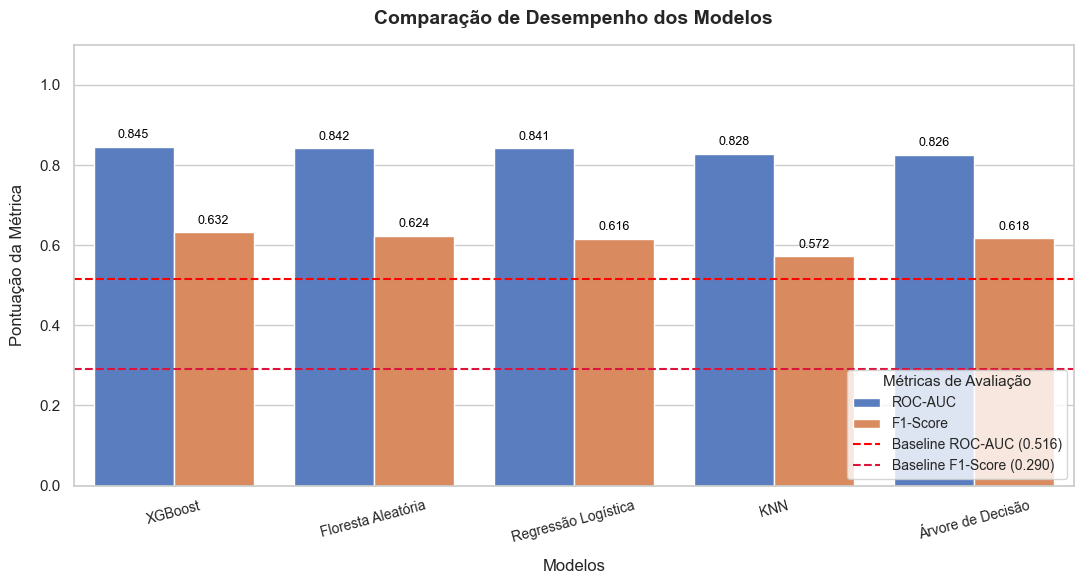

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid")
plt.figure(figsize = (11, 6))

df_melted = df_comparacao.melt(id_vars = "Modelo", value_vars = ["ROC-AUC", "F1-Score"], var_name = "Métrica", value_name = "Valor")

ax = sns.barplot(x = "Modelo", y = "Valor", hue = "Métrica", data = df_melted, palette = "muted")

plt.title("Comparação de Desempenho dos Modelos", fontsize = 14, fontweight = "bold", pad = 15)
plt.xlabel("Modelos", fontsize = 12, labelpad = 10)
plt.ylabel("Pontuação da Métrica", fontsize = 12, labelpad = 10)
plt.ylim(0, 1.1)
plt.xticks(rotation = 15, fontsize = 10)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.3f}", (p.get_x() + p.get_width() / 2., height), ha = "center", va = "bottom", fontsize = 9, color = "black",xytext = (0, 4), textcoords = "offset points")

plt.axhline(y = roc_auc_baseline, color = "red", linestyle = "--", linewidth = 1.5, label = f"Baseline ROC-AUC ({roc_auc_baseline:.3f})")
plt.axhline(y = f1_baseline, color = "crimson", linestyle = "--", linewidth = 1.5, label = f"Baseline F1-Score ({f1_baseline:.3f})")

plt.legend(title = "Métricas de Avaliação", title_fontsize = "11", fontsize = "10", loc = "lower right")
plt.tight_layout()
plt.show()

##### Figura 3 - Comparação dos desempenhos dos 5 modelos campeões nas métricas F1 Score e ROC-AUC, com modelo Baseline tracejado em vermelho. Imagem gerada com auxílio da AI Gemini.

Comparando os modelos pelos gráficos de barras da Figura $3$, nota-se que os 5 modelos ultrapassaram o baseline em todas as métricas, o que é esperado pela otimização dos treinos. No geral, o F1 Score ficou bem abaixo do ROC-AUC (não passando de 0.65 na pontuação), o que reflete a dificuldade dos modelos em tratar dados desbalanceados (mesmo utilizando estratégias como SMOTE). Mas o ROC-AUC alcançou uma pontuação acima de 0.80, um indicador positivo da eficiência dos modelos.

Observa-se que, para o F1 Score, o pior modelo é o KNN com $0.572$ pontos, enquanto o melhor é o XGBoost com $0.632$ pontos. Fora o KNN, o F1 Score dos modelos ficou parecido, variando $0.016$ pontos entre o maior (XGBoost) e o menor (Regressão Logística, $0.616$ pontos). O posicionamento do KNN pelo F1 Score indica que o KNN foi o pior modelo para lidar com dados desbalanceados, enquanto os outros modelos tiveram uma resistência maior ao desbalanço.

Em termos de ROC-AUC, o KNN obteve $0.828$ pontos. Árvore de Decisão ficou com $0.826$ pontos e foi o pior modelo. Os outros três modelos (XGBoost, Floresta Aleatória e Regressão Logística) foram os melhores, com pontuações respectivas de $0.845$, $0.842$ e $0.841$ pontos. Mesmo que o melhor modelo tenha sido XGBoost, Floresta Aleatória e Regressão Logística chegaram muito perto, com uma diferença de $0.004$ pontos entre XGBoost e Regressão Logística (o 3º melhor).

Considerando o objetivo atrelado ao dataset, os modelos tiveram uma boa eficácia em acertar quem cancelou o serviço e quem não cancelou, mas com um viés: F1 Score mostra que os modelos cometeram vários Falsos Positivos, e ROC-AUC complementa essa informação com uma pontuação alta, que só foi obtida porque os Verdadeiros Positivos cobriram os Falsos Positivos. Assim, é perceptível a influência dos dados desbalanceados.

Por fim, as curvas de ROC-AUC serão plotadas em um gráfico juntas do baseline, na Figura $4$.

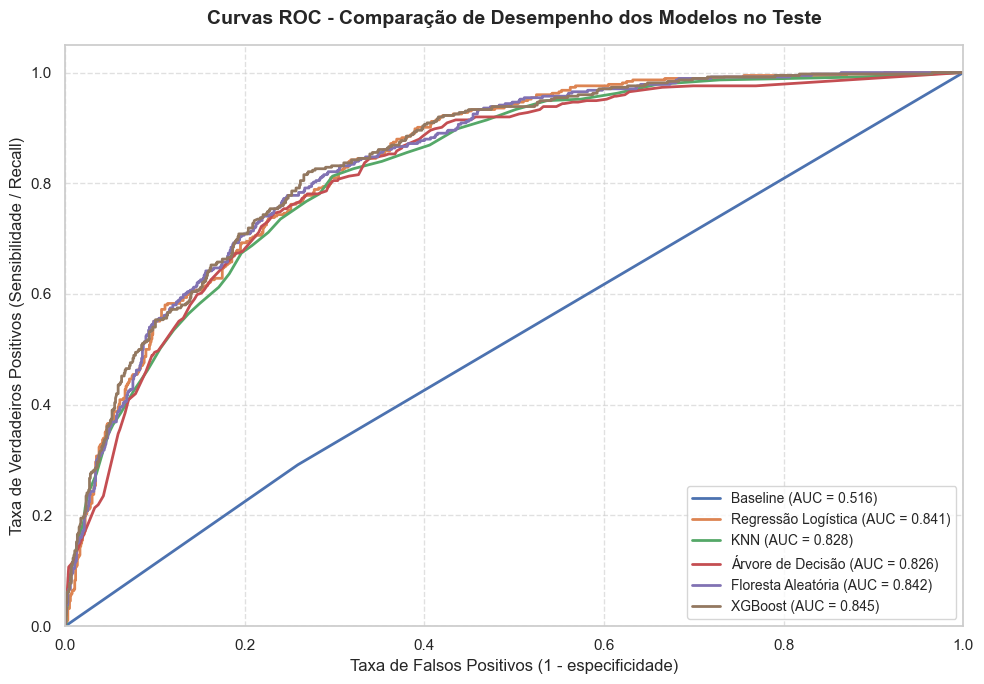

In [29]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 7))

modelos_probs = {"Baseline": y_prob_baseline, "Regressão Logística": y_prob_reg_logistica, "KNN": y_prob_knn, "Árvore de Decisão": y_prob_arvore, "Floresta Aleatória": y_prob_floresta, "XGBoost": y_prob_xgb}

for nome, y_prob in modelos_probs.items():
    fpr, tpr, thresholds = roc_curve(y_teste, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label = f"{nome} (AUC = {roc_auc:.3f})", linewidth = 2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taxa de Falsos Positivos (1 - especificidade)", fontsize = 12)
plt.ylabel("Taxa de Verdadeiros Positivos (Sensibilidade / Recall)", fontsize = 12)
plt.title("Curvas ROC - Comparação de Desempenho dos Modelos no Teste", fontsize = 14, fontweight = "bold", pad = 15)
plt.legend(loc = "lower right", fontsize = 10, frameon = True)
plt.grid(True, linestyle = "--", alpha = 0.6)

plt.tight_layout()
plt.show()

##### Figura 4 - Comparação das curvas de ROC-AUC de todos os modelos, incluindo o baseline. Imagem gerada com auxílio da AI Gemini.

A Figura $4$ permite a visualização de um resultado que já foi discutido: a pequena diferença entre o ROC-AUC dos modelos, em especial do XGBoost, da Floresta Aleatória e da Regressão Logística.

# Conclusão

Os modelos apresentaram uma boa eficiência em ROC-AUC no geral, mas o desbalanceamento dos dados é evidente com o F1 Score baixo. Além disso, desempenho geral dos modelos foi muito parecido (tanto em F1 Score quanto em ROC-AUC), demonstrando que seus resultados foram semelhantes.

É necessário discutir um tópico importante: custo computacional. Para otimizar os modelos Regressão Logística e KNN, o custo foi baixo; mas as otimizações da Árvore de Decisão e, em especial, Floresta Aleatória e XGBoost, tiveram um custo alto. Considerando desempenho, custo computacional e o objetivo do projeto, o modelo Regressão Logística se saiu surpreendentemente bem, pois obteve bons resultados de ROC-AUC e F1 Score enquanto manteve um baixo custo computacional durante a otimização. Isso reflete a importância das estratégias utilizadas - Validação Cruzada, SMOTE, Otimização de Hiperparâmetros com Seleção de Atributos - para elevar ao máximo o desempenho dos modelos, permitindo que um modelo matematicamente inferior como Regressão Logística seja elevado ao patamar de modelos teoricamente superiores. Concluímos que as estratégias utilizadas extraíram um desempenho ótimo dos modelos mais simples, enquanto os modelos mais complexos poderiam ser melhores (em comparação ao seu potencial).

# Interações com AI neste projeto

A AI Gemini foi utilizada como ferramenta auxiliar para selecionar o dataset, analisar e definir a estratégia dos itens complementares, organizar o projeto em etapas e fazer alguns ajustes nas figuras da seção Discussão de Resultados.

Link da conversa: https://share.gemini.google/VKbUPxpCNoFK

# Referências

Dataset:
- [1] - https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Seleção dos atributos mais importantes/influentes no contexto do dataset:
- [2] - Burnham, T.A., Frels, J.K. & Mahajan, V. Consumer switching costs: A typology, antecedents, and consequences. J. of the Acad. Mark. Sci. 31, 109–126 (2003). https://doi.org/10.1177/0092070302250897
- [3] - PARASURAMAN, A.; ZEITHAML, Valarie A.; BERRY, Leonard L. SERVQUAL: A multiple-item scale for measuring consumer perceptions of service quality. Journal of Retailing, v. 64, n. 1, p. 12-40, 1988.